## 0. Configuration and Imports

In [1]:
# Installation (uncomment if needed):
# !pip install -q pandas numpy matplotlib seaborn scikit-learn imbalanced-learn xgboost shap lime kagglehub joblib

import os, time, warnings, joblib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.svm import OneClassSVM
from sklearn.neural_network import MLPRegressor
from sklearn.cluster import DBSCAN
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             fbeta_score, matthews_corrcoef, precision_score, recall_score, log_loss)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE, BorderlineSMOTE, ADASYN
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 10})

# ------------------------- GLOBAL PARAMETERS -------------------------
SEED       = 42
DATA_DIR   = Path("data")     # folder containing fraudTrain.csv and fraudTest.csv (otherwise Kaggle download)
N_WINDOW   = 200_000          # continuous chronological window for the pipeline (150,000 to 250,000)
DENSITY_N  = 20_000           # sub-window (end of train) for LOF and One-Class SVM (computationally intensive)
DBSCAN_N   = 10_000           # sub-window for DBSCAN (transductive approach)
CA         = 10.0             # administrative cost per analyzed alert (in $)
K_DAILY    = 100              # daily alert budget (k)
K_LIST     = [50, 100, 200]   # alert budgets tested for sensitivity analysis
GAP_CAP    = 30 * 24 * 3600   # cap (30 days) for time_since_last_tx and default value for first transaction of a card
SHAP_N     = 3000             # sample size for global explanations
TUNE_XGB   = True             # lightweight XGBoost hyperparameter tuning on validation set
np.random.seed(SEED)
#/kaggle/input/datasets/kartik2112/fraud-detection

# STEP 1 — Data and Exploratory Analysis
## 1.1 Loading and Chronological Sorting

In [2]:
def locate_data():
    for d in [DATA_DIR, Path("."), Path("/kaggle/input/fraud-detection")]:
        if (d / "fraudTrain.csv").exists() and (d / "fraudTest.csv").exists():
            return d
    import kagglehub                                   # automatic download
    return Path(kagglehub.dataset_download("kartik2112/fraud-detection"))

data_path = locate_data()
t0 = time.time()
raw_tr = pd.read_csv(data_path / "fraudTrain.csv", parse_dates=["trans_date_trans_time"])
raw_te = pd.read_csv(data_path / "fraudTest.csv",  parse_dates=["trans_date_trans_time"])
df = (pd.concat([raw_tr, raw_te], ignore_index=True)
        .sort_values("trans_date_trans_time", kind="stable")
        .reset_index(drop=True))
print(f"Chargé en {time.time()-t0:.0f}s — {df.shape[0]:,} transactions, {df.shape[1]} colonnes")
print(f"Période : {df.trans_date_trans_time.min()}  →  {df.trans_date_trans_time.max()}")
print(f"Cartes distinctes : {df.cc_num.nunique():,} | marchands : {df.merchant.nunique():,} | valeurs manquantes : {int(df.isna().sum().sum())}")
display(df.head(3).T)

Chargé en 15s — 1,852,394 transactions, 23 colonnes
Période : 2019-01-01 00:00:18  →  2020-12-31 23:59:34
Cartes distinctes : 999 | marchands : 693 | valeurs manquantes : 0


,0,1,2
Unnamed: 0,0,1,2
trans_date_trans_time,2019-01-01 00:00:18,2019-01-01 00:00:44,2019-01-01 00:00:51
cc_num,2703186189652095,630423337322,38859492057661
merchant,"fraud_Rippin, Kub and Mann","fraud_Heller, Gutmann and Zieme",fraud_Lind-Buckridge
category,misc_net,grocery_pos,entertainment
amt,4.97,107.23,220.11
first,Jennifer,Stephanie,Edward
last,Banks,Gill,Sanchez
gender,F,F,M
street,561 Perry Cove,43039 Riley Greens Suite 393,594 White Dale Suite 530


## 1.2 Extreme Imbalance: Why Accuracy is Misleading

In [3]:
fraud_rate = df.is_fraud.mean()
total_fraud_amt = df.loc[df.is_fraud == 1, "amt"].sum()
naive = pd.Series({
    "Taux de fraude global": f"{fraud_rate:.3%}",
    "Nombre de fraudes": f"{int(df.is_fraud.sum()):,}",
    "Accuracy du modèle naïf (toujours 0)": f"{1-fraud_rate:.3%}",
    "Rappel du modèle naïf": "0 %",
    "Pertes laissées passer ($)": f"{total_fraud_amt:,.0f}",
}, name="Modèle naïf")
display(naive.to_frame())

,Modèle naïf
Taux de fraude global,0.521%
Nombre de fraudes,"9,651"
Accuracy du modèle naïf (toujours 0),99.479%
Rappel du modèle naïf,0 %
Pertes laissées passer ($),"5,121,413"


## 1.3 Required Exploratory Visualizations

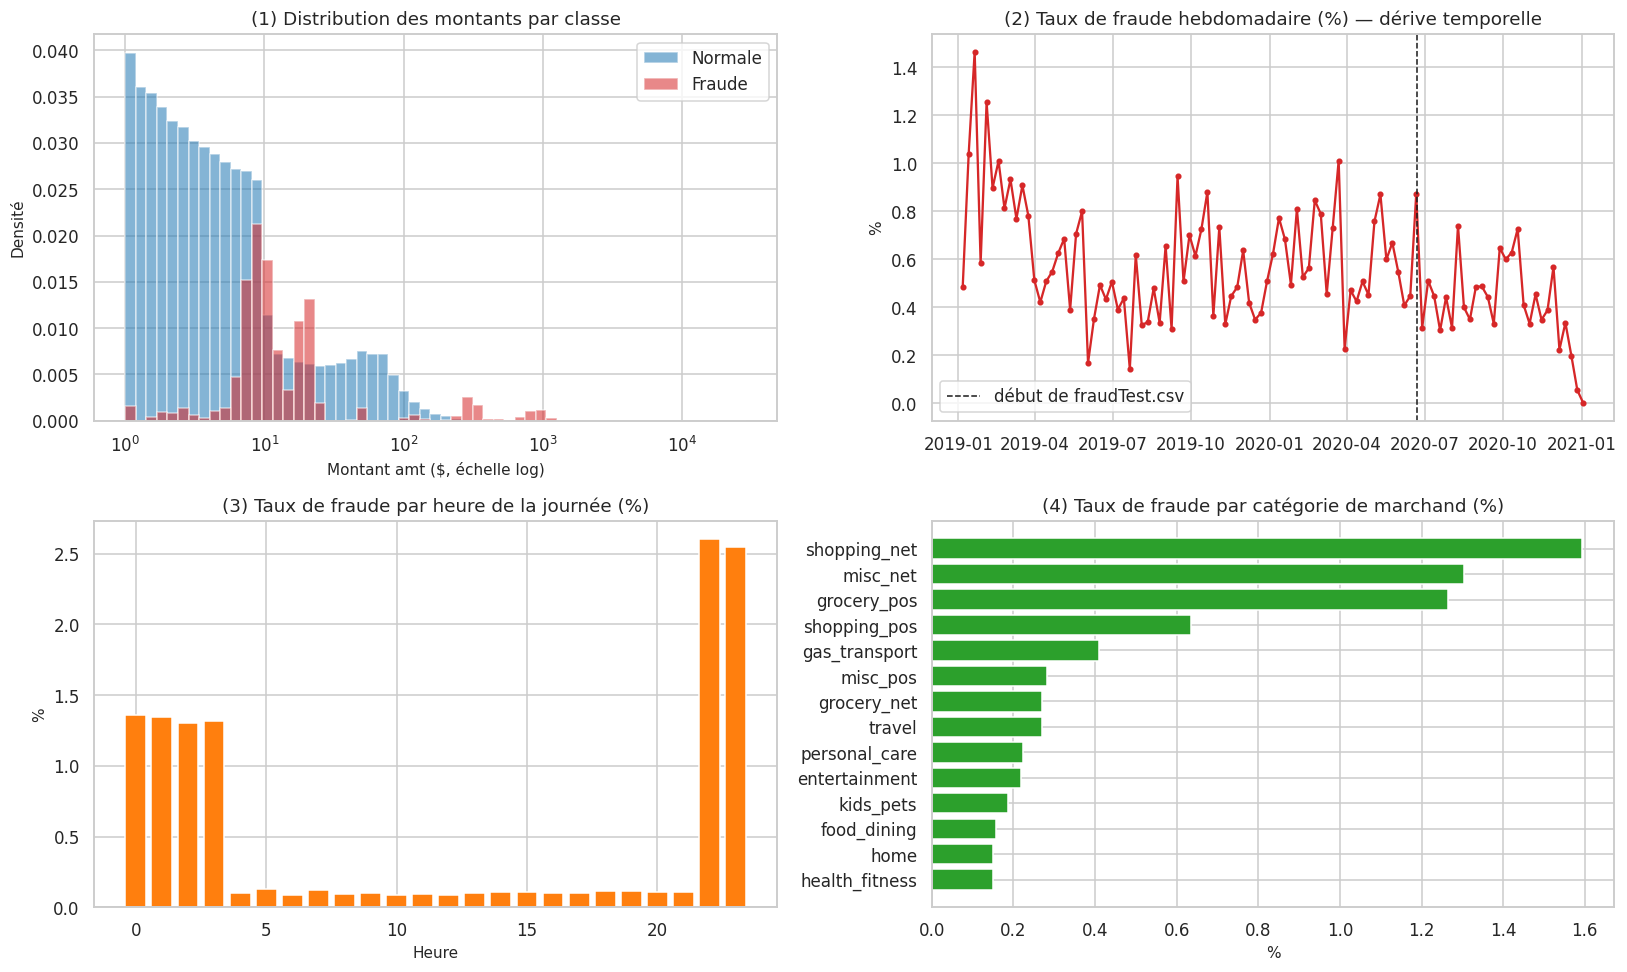

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,1842743.0,67.65,153.55,1.00,9.61,47.24,82.56,28948.90
1,9651.0,530.66,391.03,1.06,240.08,390.00,902.36,1376.04


In [4]:
fig, ax = plt.subplots(2, 2, figsize=(15, 9))

# (1) Amounts by class (log scale due to highly skewed distribution)
bins = np.logspace(0, np.log10(df.amt.max()), 60)
for c, lab, col in [(0, "Normale", "tab:blue"), (1, "Fraude", "tab:red")]:
    ax[0, 0].hist(df.loc[df.is_fraud == c, "amt"], bins=bins, density=True, alpha=.55, label=lab, color=col)
ax[0, 0].set_xscale("log"); ax[0, 0].set_xlabel("Montant amt ($, échelle log)"); ax[0, 0].set_ylabel("Densité")
ax[0, 0].set_title("(1) Distribution des montants par classe"); ax[0, 0].legend()

# (2) Fraud rate evolution (weekly) + original train/test split boundary
wk = df.set_index("trans_date_trans_time")["is_fraud"].resample("W").agg(["mean", "sum"])
ax[0, 1].plot(wk.index, wk["mean"] * 100, marker="o", ms=3, color="tab:red")
ax[0, 1].axvline(raw_te.trans_date_trans_time.min(), color="k", ls="--", lw=1, label="début de fraudTest.csv")
ax[0, 1].set_title("(2) Taux de fraude hebdomadaire (%) — dérive temporelle"); ax[0, 1].set_ylabel("%"); ax[0, 1].legend()

# (3) Fraud rate by hour of day
by_hour = df.groupby(df.trans_date_trans_time.dt.hour)["is_fraud"].mean() * 100
ax[1, 0].bar(by_hour.index, by_hour.values, color="tab:orange")
ax[1, 0].set_title("(3) Taux de fraude par heure de la journée (%)"); ax[1, 0].set_xlabel("Heure"); ax[1, 0].set_ylabel("%")

# (4) Fraud rate by merchant category
by_cat = (df.groupby("category")["is_fraud"].mean() * 100).sort_values()
ax[1, 1].barh(by_cat.index, by_cat.values, color="tab:green")
ax[1, 1].set_title("(4) Taux de fraude par catégorie de marchand (%)"); ax[1, 1].set_xlabel("%")
plt.tight_layout(); plt.show()

display(df.groupby("is_fraud")["amt"].describe().round(2))

# STEP 2 — Leak-Free Features, Splitting, and Class Imbalance
## 2.1 Feature Engineering (Strictly Using the **Past**)

In [5]:
def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0088
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi, dlmb = p2 - p1, np.radians(lon2) - np.radians(lon1)
    a = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dlmb / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

def add_time_features(d):
    d = d.copy()
    t = d["trans_date_trans_time"]
    d["hour"] = t.dt.hour
    d["hour_sin"] = np.sin(2 * np.pi * d["hour"] / 24)
    d["hour_cos"] = np.cos(2 * np.pi * d["hour"] / 24)
    d["day_of_week"] = t.dt.dayofweek
    d["dist_to_merchant"] = haversine(d["lat"], d["long"], d["merch_lat"], d["merch_long"])
    return d

BEH_COLS = ["tx_count_1h", "tx_count_24h", "amt_ratio_30d", "time_since_last_tx", "speed_kmh"]

def add_behavioral_features(d):
    """Behavioral features per card, using rolling windows that look only at the past."""
    g = d.sort_values(["cc_num", "trans_date_trans_time"], kind="stable").copy()
    ts = (g["trans_date_trans_time"] - pd.Timestamp("1970-01-01")).dt.total_seconds().to_numpy()
    cc, amt = g["cc_num"].to_numpy(), g["amt"].to_numpy(float)
    mlat, mlon = g["merch_lat"].to_numpy(float), g["merch_long"].to_numpy(float)
    n = len(g)
    c1, c24 = np.zeros(n), np.zeros(n)
    ratio, speed = np.ones(n), np.zeros(n)
    gap = np.full(n, float(GAP_CAP))
    bounds = np.flatnonzero(np.r_[True, cc[1:] != cc[:-1], True])      # group boundaries (cards)
    for a, b in zip(bounds[:-1], bounds[1:]):
        t, x, m = ts[a:b], amt[a:b], b - a
        idx = np.arange(m)
        lo1  = np.searchsorted(t, t - 3600,        side="left")      # 1st index in [t-1h, t]
        lo24 = np.searchsorted(t, t - 86400,       side="left")
        lo30 = np.searchsorted(t, t - 30 * 86400,  side="left")
        c1[a:b], c24[a:b] = idx - lo1, idx - lo24                     # number of PAST transactions in the window
        cs = np.r_[0.0, np.cumsum(x)]
        cnt = idx - lo30
        s = cs[idx] - cs[lo30]                                        # sum of amounts over [lo30, idx-1]: excludes current transaction
        mean_past = s / np.maximum(cnt, 1)
        ratio[a:b] = np.where(cnt > 0, x / np.maximum(mean_past, 0.01), 1.0)   # 1.0 = "no history"
        dts = t[1:] - t[:-1]
        gap[a + 1:b] = np.minimum(dts, GAP_CAP)
        dist = haversine(mlat[a:b - 1], mlon[a:b - 1], mlat[a + 1:b], mlon[a + 1:b])
        speed[a + 1:b] = np.minimum(dist / np.maximum(dts / 3600, 1 / 60), 5000)
    g["tx_count_1h"], g["tx_count_24h"] = c1, c24
    g["amt_ratio_30d"], g["time_since_last_tx"], g["speed_kmh"] = ratio, gap, speed
    return g.sort_values("trans_date_trans_time", kind="stable")

t0 = time.time()
feat = add_behavioral_features(add_time_features(df))
print(f"Variables calculées sur {len(feat):,} transactions en {time.time()-t0:.0f}s")
display(feat[["amt", "hour", "tx_count_1h", "tx_count_24h", "amt_ratio_30d", "time_since_last_tx", "dist_to_merchant", "speed_kmh"]].describe().T.round(2))

Variables calculées sur 1,852,394 transactions en 7s


,count,mean,std,min,25%,50%,75%,max
amt,1852394.0,70.06,159.25,1.00,9.64,47.45,83.10,28948.90
hour,1852394.0,12.81,6.82,0.00,7.00,14.00,19.00,23.00
tx_count_1h,1852394.0,0.20,0.48,0.00,0.00,0.00,0.00,8.00
tx_count_24h,1852394.0,4.11,3.26,0.00,2.00,3.00,6.00,35.00
amt_ratio_30d,1852394.0,1.06,2.74,0.00,0.17,0.67,1.26,676.39
time_since_last_tx,1852394.0,32320.67,74759.63,0.00,5701.00,15710.00,38194.00,2592000.00
dist_to_merchant,1852394.0,76.11,29.12,0.02,55.32,78.22,98.51,152.12
speed_kmh,1852394.0,113.37,425.38,0.00,7.97,21.09,62.05,5000.00


### Leak-Free Verification ("Leakage Test")

In [6]:
T_cut = feat["trans_date_trans_time"].quantile(0.5)
sub = df[df.trans_date_trans_time < T_cut]
feat_sub = add_behavioral_features(sub)
a = feat.loc[sub.index, BEH_COLS].sort_index().to_numpy()
b = feat_sub.loc[sub.index, BEH_COLS].sort_index().to_numpy()
print("Variables identiques avec / sans le futur :", np.allclose(a, b))
assert np.allclose(a, b), "FUITE DÉTECTÉE : une variable utilise des informations du futur"

Variables identiques avec / sans le futur : True


## 2.2 Continuous Chronological Window and Dropping Identifiers

In [7]:
NUM_FEATS = ["amt", "hour_sin", "hour_cos", "day_of_week", "tx_count_1h", "tx_count_24h",
             "amt_ratio_30d", "time_since_last_tx", "dist_to_merchant", "speed_kmh"]
CAT_FEATS = ["category"]
ID_COLS = ["Unnamed: 0", "trans_num", "first", "last", "street", "cc_num"]

feat = feat.drop(columns=[c for c in ID_COLS if c in feat.columns])
WINDOW_END = "2020-10-15"      # before the late-2020 fraud collapse
N_WINDOW   = 250_000
win = feat[feat.trans_date_trans_time <= WINDOW_END].iloc[-N_WINDOW:]                                   # continuous window = the last N_WINDOW transactions
data = win[["trans_date_trans_time", "is_fraud", "hour"] + NUM_FEATS + CAT_FEATS].reset_index(drop=True)
print(f"Fenêtre : {len(data):,} transactions | {data.trans_date_trans_time.min()} → {data.trans_date_trans_time.max()}")
print(f"Fraudes : {int(data.is_fraud.sum())} ({data.is_fraud.mean():.3%})")

Fenêtre : 250,000 transactions | 2020-07-10 22:04:57 → 2020-10-14 23:59:54
Fraudes : 1191 (0.476%)


## 2.3 Chronological Split (60% Train / 20% Validation / 20% Test)

In [8]:
n = len(data); i_tr, i_va = int(0.6 * n), int(0.8 * n)
train, val, test = data.iloc[:i_tr].copy(), data.iloc[i_tr:i_va].copy(), data.iloc[i_va:].copy()

split_tab = pd.DataFrame({
    "lignes": [len(s) for s in (train, val, test)],
    "début": [s.trans_date_trans_time.min().date() for s in (train, val, test)],
    "fin": [s.trans_date_trans_time.max().date() for s in (train, val, test)],
    "fraudes": [int(s.is_fraud.sum()) for s in (train, val, test)],
    "taux fraude": [f"{s.is_fraud.mean():.3%}" for s in (train, val, test)],
}, index=["Train (60 %)", "Validation (20 %)", "Test (20 %)"])
display(split_tab)

ytr, yva, yte = (s.is_fraud.to_numpy() for s in (train, val, test))
amt_tr, amt_va, amt_te = (s.amt.to_numpy() for s in (train, val, test))
days_va = val.trans_date_trans_time.dt.normalize().to_numpy()
days_te = test.trans_date_trans_time.dt.normalize().to_numpy()
print(f"Jours dans validation : {len(np.unique(days_va))} | test : {len(np.unique(days_te))}")
print(f"Test : ~{len(test)/len(np.unique(days_te)):.0f} transactions/jour, ~{yte.sum()/len(np.unique(days_te)):.1f} fraudes/jour")

,lignes,début,fin,fraudes,taux fraude
Train (60 %),150000,2020-07-10,2020-09-01,657,0.438%
Validation (20 %),50000,2020-09-01,2020-09-22,212,0.424%
Test (20 %),50000,2020-09-22,2020-10-14,322,0.644%


Jours dans validation : 22 | test : 23
Test : ~2174 transactions/jour, ~14.0 fraudes/jour


## 2.4 Normalization and Encoding (Fitted on **Train Only**)

In [9]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), NUM_FEATS),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATS),
])
Xtr = preprocessor.fit_transform(train[NUM_FEATS + CAT_FEATS])      # fit ONLY on the training set
Xva = preprocessor.transform(val[NUM_FEATS + CAT_FEATS])
Xte = preprocessor.transform(test[NUM_FEATS + CAT_FEATS])
feature_names = [c.split("__", 1)[1] for c in preprocessor.get_feature_names_out()]
print("Dimension des données :", Xtr.shape, "| noms :", feature_names[:12], "...")

Xtr_df = pd.DataFrame(Xtr, columns=feature_names)
Xva_df = pd.DataFrame(Xva, columns=feature_names)
Xte_df = pd.DataFrame(Xte, columns=feature_names)
# "Human-readable" version (original units) for explanation plots and reason codes
def to_raw(frame, X):
    onehot = pd.DataFrame(X[:, len(NUM_FEATS):], columns=feature_names[len(NUM_FEATS):])
    return pd.concat([frame[NUM_FEATS].reset_index(drop=True), onehot], axis=1)
raw_te = to_raw(test, Xte)

Dimension des données : (150000, 24) | noms : ['amt', 'hour_sin', 'hour_cos', 'day_of_week', 'tx_count_1h', 'tx_count_24h', 'amt_ratio_30d', 'time_since_last_tx', 'dist_to_merchant', 'speed_kmh', 'category_entertainment', 'category_food_dining'] ...


## 2.5 Benchmark of Class Imbalance Strategies

In [10]:
def bayes_correct(ps, beta):
    return beta * ps / (beta * ps - ps + 1)

XGB_PARAMS = dict(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8, min_child_weight=1)

def make_model(kind, spw=1.0, cw=None):
    if kind == "logreg":
        return LogisticRegression(max_iter=1000, class_weight=cw, random_state=SEED)
    if kind == "xgb":
        return XGBClassifier(**XGB_PARAMS, scale_pos_weight=spw, tree_method="hist",
                             eval_metric="aucpr", random_state=SEED, n_jobs=-1)
    raise ValueError(kind)

STRATEGIES = {
    "1. Sans rééchantillonnage": dict(kind="none"),
    "2. Pondération des classes": dict(kind="weight"),
    "3. Sous-éch. 1:1":  dict(kind="rus", ratio=1),
    "3. Sous-éch. 1:5":  dict(kind="rus", ratio=5),
    "3. Sous-éch. 1:10": dict(kind="rus", ratio=10),
    "3. Sous-éch. 1:20": dict(kind="rus", ratio=20),
    "4. SMOTE":            dict(kind="smote"),
    "4. Borderline-SMOTE": dict(kind="borderline"),
    "4. ADASYN":           dict(kind="adasyn"),
}
OVERSAMPLE_RATIO = 0.1   # after oversampling: fraud count = 10% of normal transactions

def fit_strategy(model_kind, strat, X, y):
    """Returns (model fitted on the resampled TRAIN set, correction beta or None)."""
    n_pos, n_neg = int((y == 1).sum()), int((y == 0).sum())
    cw, spw, beta, sampler = None, 1.0, None, None
    t = strat["kind"]
    if t == "weight":
        cw, spw = "balanced", n_neg / n_pos
    elif t == "rus":
        sampler = RandomUnderSampler(sampling_strategy=1 / strat["ratio"], random_state=SEED)
        beta = (strat["ratio"] * n_pos) / n_neg           # fraction of retained normal transactions m/|N|
    elif t == "smote":
        sampler = SMOTE(sampling_strategy=OVERSAMPLE_RATIO, random_state=SEED)
    elif t == "borderline":
        sampler = BorderlineSMOTE(sampling_strategy=OVERSAMPLE_RATIO, random_state=SEED)
    elif t == "adasyn":
        sampler = ADASYN(sampling_strategy=OVERSAMPLE_RATIO, random_state=SEED)
    clf = make_model(model_kind, spw, cw)
    pipe = ImbPipeline([("sampler", sampler), ("clf", clf)]) if sampler is not None else clf
    pipe.fit(X, y)
    return pipe, beta

def get_clf(pipe):
    return pipe.steps[-1][1] if hasattr(pipe, "steps") else pipe

def sup_score(pipe, beta, X):
    p = pipe.predict_proba(X)[:, 1]
    return bayes_correct(p, beta) if beta is not None else p

rows = []
for mk, mname in [("logreg", "Régression logistique"), ("xgb", "XGBoost")]:
    for sname, strat in STRATEGIES.items():
        t0 = time.time()
        pipe, beta = fit_strategy(mk, strat, Xtr, ytr)
        raw_p = pipe.predict_proba(Xva)[:, 1]
        p = bayes_correct(raw_p, beta) if beta is not None else raw_p
        rows.append(dict(Modèle=mname, Stratégie=sname, **{"PR-AUC (val)": average_precision_score(yva, p),
                         "ROC-AUC (val)": roc_auc_score(yva, p),
                         "Proba moy. prédite (brute)": raw_p.mean(), "Proba moy. (corrigée)": p.mean(),
                         "Taux réel": yva.mean(), "Temps (s)": time.time() - t0}))
bench = pd.DataFrame(rows)
display(bench.round(4))

,Modèle,Stratégie,PR-AUC (val),ROC-AUC (val),Proba moy. prédite (brute),Proba moy. (corrigée),Taux réel,Temps (s)
0,Régression logistique,1. Sans rééchantillonnage,0.4105,0.9247,0.0044,0.0044,0.0042,0.8887
1,Régression logistique,2. Pondération des classes,0.2175,0.9687,0.1768,0.1768,0.0042,1.7686
2,Régression logistique,3. Sous-éch. 1:1,0.2257,0.9690,0.1811,0.0063,0.0042,0.1790
3,Régression logistique,3. Sous-éch. 1:5,0.2668,0.9639,0.0695,0.0056,0.0042,0.1041
4,Régression logistique,3. Sous-éch. 1:10,0.3042,0.9604,0.0423,0.0053,0.0042,0.1502
5,Régression logistique,3. Sous-éch. 1:20,0.3503,0.9555,0.0258,0.0049,0.0042,0.1541
6,Régression logistique,4. SMOTE,0.3523,0.9572,0.0408,0.0408,0.0042,1.1610
7,Régression logistique,4. Borderline-SMOTE,0.3855,0.9502,0.0293,0.0293,0.0042,2.1398
8,Régression logistique,4. ADASYN,0.3382,0.9576,0.0540,0.0540,0.0042,1.2868
9,XGBoost,1. Sans rééchantillonnage,0.8242,0.9959,0.0038,0.0038,0.0042,3.0003


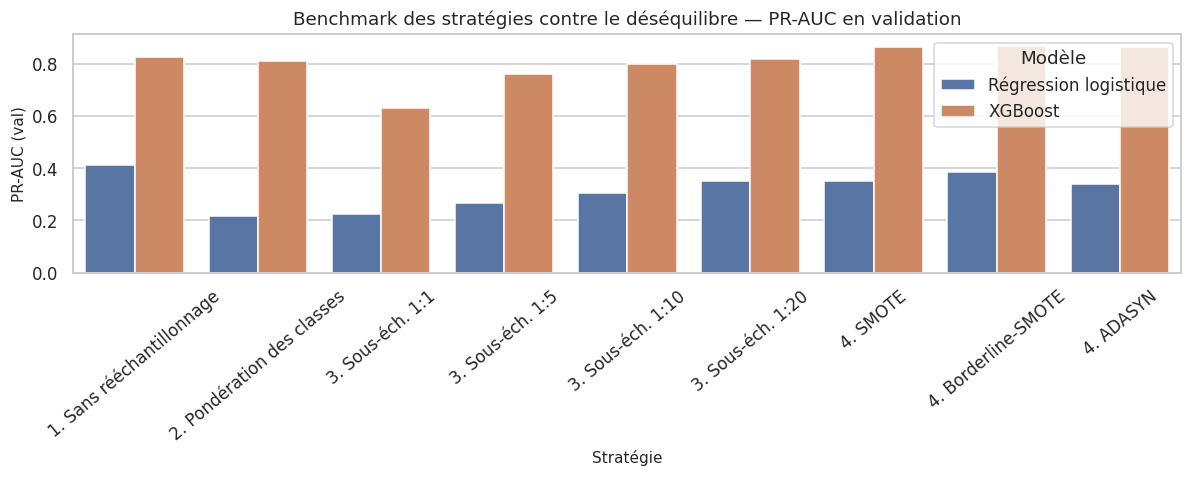

Stratégie retenue (max PR-AUC validation) : {'Régression logistique': '1. Sans rééchantillonnage', 'XGBoost': '4. Borderline-SMOTE'}


In [11]:
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(data=bench, x="Stratégie", y="PR-AUC (val)", hue="Modèle", ax=ax)
ax.set_title("Benchmark des stratégies contre le déséquilibre — PR-AUC en validation")
ax.tick_params(axis="x", rotation=40); plt.tight_layout(); plt.show()

best_strategy = {}
for mname, g in bench.groupby("Modèle"):
    best_strategy[mname] = g.loc[g["PR-AUC (val)"].idxmax(), "Stratégie"]
print("Stratégie retenue (max PR-AUC validation) :", best_strategy)

## Lightweight XGBoost Tuning (Validation Set Only)

In [12]:
if TUNE_XGB:
    grid = [dict(max_depth=4, learning_rate=0.1,  n_estimators=300),
            dict(max_depth=6, learning_rate=0.1,  n_estimators=300),
            dict(max_depth=8, learning_rate=0.1,  n_estimators=300),
            dict(max_depth=6, learning_rate=0.05, n_estimators=600),
            dict(max_depth=8, learning_rate=0.05, n_estimators=600)]
    res, strat_x = [], STRATEGIES[best_strategy["XGBoost"]]
    base_params = dict(XGB_PARAMS)
    for g in grid:
        XGB_PARAMS.update(g)
        pipe, beta = fit_strategy("xgb", strat_x, Xtr, ytr)
        res.append({**g, "PR-AUC (val)": average_precision_score(yva, sup_score(pipe, beta, Xva))})
    tune = pd.DataFrame(res).sort_values("PR-AUC (val)", ascending=False)
    display(tune.round(4))
    XGB_PARAMS.clear(); XGB_PARAMS.update(base_params)
    XGB_PARAMS.update({k: int(v) if k != "learning_rate" else float(v) for k, v in tune.iloc[0][["max_depth", "learning_rate", "n_estimators"]].items()})
    print("Hyperparamètres XGBoost retenus :", XGB_PARAMS)

,max_depth,learning_rate,n_estimators,PR-AUC (val)
3,6,0.05,600,0.8712
0,4,0.10,300,0.8696
2,8,0.10,300,0.8685
1,6,0.10,300,0.8684
4,8,0.05,600,0.8676


Hyperparamètres XGBoost retenus : {'n_estimators': 600, 'max_depth': 6, 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree': 0.8, 'min_child_weight': 1}


# STEP 3 — Supervised Modeling vs Anomaly Detection
## 3.1 Supervised Models

In [13]:
MODELS = {}   # name -> dict(pipe, beta, family)
t0 = time.time()
pipe, beta = fit_strategy("logreg", STRATEGIES[best_strategy["Régression logistique"]], Xtr, ytr)
MODELS["Régression logistique"] = dict(pipe=pipe, beta=beta, family="Supervisé")

pipe, beta = fit_strategy("xgb", STRATEGIES[best_strategy["XGBoost"]], Xtr, ytr)
MODELS["XGBoost"] = dict(pipe=pipe, beta=beta, family="Supervisé")

rf = RandomForestClassifier(n_estimators=200, max_depth=14, min_samples_leaf=5,
                            class_weight="balanced_subsample", n_jobs=-1, random_state=SEED).fit(Xtr, ytr)
MODELS["Random Forest"] = dict(pipe=rf, beta=None, family="Supervisé")
print(f"Modèles supervisés ajustés en {time.time()-t0:.0f}s")

SCORES = {}   # name -> dict(val=..., test=..., family=...) ; scores in [0,1]
for name, m in MODELS.items():
    SCORES[name] = dict(val=sup_score(m["pipe"], m["beta"], Xva), test=sup_score(m["pipe"], m["beta"], Xte), family=m["family"])
    print(f"{name:24s} PR-AUC val = {average_precision_score(yva, SCORES[name]['val']):.4f}")

Modèles supervisés ajustés en 29s
Régression logistique    PR-AUC val = 0.4105
XGBoost                  PR-AUC val = 0.8712
Random Forest            PR-AUC val = 0.7159


## 3.2 Unsupervised Models
### Isolation Forest

In [14]:
def ecdf_normalize(ref, s):
    ref_sorted = np.sort(ref)
    return np.searchsorted(ref_sorted, s, side="right") / len(ref_sorted)

def register_unsup(name, raw_val, raw_test):
    SCORES[name] = dict(val=ecdf_normalize(raw_val, raw_val), test=ecdf_normalize(raw_val, raw_test), family="Non supervisé")
    print(f"{name:24s} PR-AUC val = {average_precision_score(yva, SCORES[name]['val']):.4f}")

t0 = time.time()
iso = IsolationForest(n_estimators=100, max_samples=256, random_state=SEED).fit(Xtr)
register_unsup("Isolation Forest", -iso.score_samples(Xva), -iso.score_samples(Xte))
print(f"Temps : {time.time()-t0:.0f}s")

Isolation Forest         PR-AUC val = 0.1254
Temps : 1s


### Local Outlier Factor (LOF) — Local Density

In [15]:
dens = slice(len(Xtr) - DENSITY_N, len(Xtr))
Xd, yd = Xtr[dens], ytr[dens]

t0 = time.time()
lof = LocalOutlierFactor(n_neighbors=20, novelty=True, n_jobs=-1).fit(Xd)
register_unsup("LOF", -lof.score_samples(Xva), -lof.score_samples(Xte))
print(f"Temps : {time.time()-t0:.0f}s")

LOF                      PR-AUC val = 0.0806
Temps : 9s


### Autoencoder (Reconstruction Error)

In [16]:
t0 = time.time()
X_normal = Xtr[ytr == 0]
ae = MLPRegressor(hidden_layer_sizes=(8, 3, 8), max_iter=500, early_stopping=True, n_iter_no_change=10,
                  random_state=SEED).fit(X_normal, X_normal)
recon_err = lambda X: ((X - ae.predict(X)) ** 2).mean(axis=1)
register_unsup("Autoencodeur", recon_err(Xva), recon_err(Xte))
print(f"Temps : {time.time()-t0:.0f}s | itérations : {ae.n_iter_}")

Autoencodeur             PR-AUC val = 0.1309
Temps : 63s | itérations : 144


### One-Class SVM

In [17]:
t0 = time.time()
ocsvm = OneClassSVM(kernel="rbf", nu=0.01, gamma="scale").fit(Xd[yd == 0])
register_unsup("One-Class SVM", -ocsvm.decision_function(Xva), -ocsvm.decision_function(Xte))
print(f"Temps : {time.time()-t0:.0f}s")

One-Class SVM            PR-AUC val = 0.1253
Temps : 3s


### DBSCAN

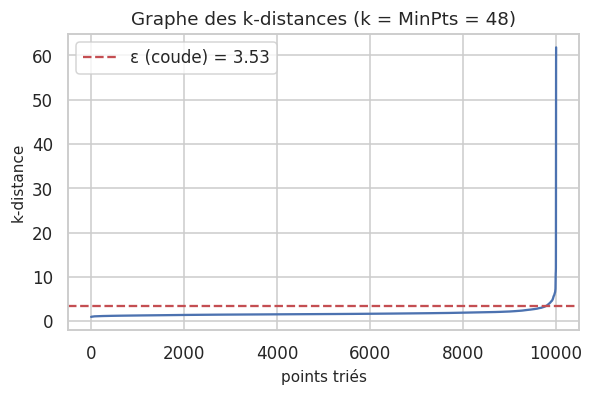

DBSCAN val: 0.94% de points « bruit » (alertes)
DBSCAN test: 1.05% de points « bruit » (alertes)


In [18]:
def elbow_value(y):
    """Point of the (increasing, convex) curve that is farthest from the chord."""
    x = np.arange(len(y), dtype=float)
    xn = (x - x.min()) / (x.max() - x.min()); yn = (y - y.min()) / (y.max() - y.min())
    d = np.abs((yn[-1] - yn[0]) * xn - (xn[-1] - xn[0]) * yn + xn[-1] * yn[0] - yn[-1] * xn[0])
    return y[np.argmax(d)]

d_dim = Xtr.shape[1]
MINPTS = 2 * d_dim
Xv_sub, yv_sub, amt_v_sub = Xva[:DBSCAN_N], yva[:DBSCAN_N], amt_va[:DBSCAN_N]
Xt_sub, yt_sub, amt_t_sub = Xte[:DBSCAN_N], yte[:DBSCAN_N], amt_te[:DBSCAN_N]

nn = NearestNeighbors(n_neighbors=MINPTS).fit(Xv_sub)
kdist = np.sort(nn.kneighbors(Xv_sub)[0][:, -1])
eps = float(elbow_value(kdist))
plt.figure(figsize=(6, 3.5)); plt.plot(kdist); plt.axhline(eps, color="r", ls="--", label=f"ε (coude) = {eps:.2f}")
plt.title(f"Graphe des k-distances (k = MinPts = {MINPTS})"); plt.xlabel("points triés"); plt.ylabel("k-distance"); plt.legend(); plt.show()

db_pred = {}
for lab, Xs in [("val", Xv_sub), ("test", Xt_sub)]:
    db_pred[lab] = (DBSCAN(eps=eps, min_samples=MINPTS, n_jobs=-1).fit_predict(Xs) == -1).astype(int)  # noise = alert
    print(f"DBSCAN {lab}: {db_pred[lab].mean():.2%} de points « bruit » (alertes)")

# STEP 4 — Evaluation and Business Cost Threshold Optimization
## 4.1 Metrics and Utility Functions

In [19]:
def topk_daily(y, s, days, k):
    d = pd.DataFrame({"y": y, "s": s, "day": days}).sort_values(["day", "s"], ascending=[True, False])
    d["rk"] = d.groupby("day").cumcount()
    top = d[d["rk"] < k]
    tp = top["y"].sum()
    return tp / len(top), tp / d["y"].sum()

def cost_curve(y, amt, s, Ca):
    """Exact C(τ) for every candidate threshold (alert if s >= τ), computed with cumulative sums."""
    order = np.argsort(s); s_sorted = s[order]
    cs = np.r_[0.0, np.cumsum((amt * y)[order])]                    # cs[i] = fraudulent amount of the i lowest scores
    thr = np.unique(s_sorted)
    idx = np.r_[np.searchsorted(s_sorted, thr, side="left"), len(s)]
    thr = np.r_[thr, thr[-1] + 1e-9]                                 # last threshold: zero alerts
    n_alert = len(s) - idx
    return pd.DataFrame({"tau": thr, "missed": cs[idx], "n_alerts": n_alert, "cost": cs[idx] + Ca * n_alert})

def cost_at(y, amt, s, tau, Ca):
    alert = s >= tau
    missed = amt[(y == 1) & ~alert].sum()
    return missed + Ca * alert.sum(), alert

def evaluate(name, sv, st, Ca=CA, k=K_DAILY):
    cv = cost_curve(yva, amt_va, sv, Ca)
    tau = float(cv.loc[cv["cost"].idxmin(), "tau"])                  # τ* selected on VALIDATION set
    cost_t, alert_t = cost_at(yte, amt_te, st, tau, Ca)
    _, alert_v = cost_at(yva, amt_va, sv, tau, Ca)
    base_t = amt_te[yte == 1].sum()                                  # "without model": all fraud amounts are lost
    pk, rk = topk_daily(yte, st, days_te, k)
    return {"Modèle": name, "Famille": SCORES[name]["family"] if name in SCORES else "Non supervisé",
            "PR-AUC val": average_precision_score(yva, sv), "ROC-AUC val": roc_auc_score(yva, sv),
            "PR-AUC test": average_precision_score(yte, st), "ROC-AUC test": roc_auc_score(yte, st),
            f"P@{k} test": pk, f"R@{k} test": rk, "τ*": tau,
            "F2 val": fbeta_score(yva, alert_v, beta=2), "F2 test": fbeta_score(yte, alert_t, beta=2),
            "MCC test": matthews_corrcoef(yte, alert_t),
            "Alertes test": int(alert_t.sum()), "Coût test ($)": cost_t, "Sans modèle ($)": base_t,
            "Économie ($)": base_t - cost_t, "Économie (%)": 100 * (base_t - cost_t) / base_t}

## 4.2 Master Comparison Table (Validation and Test Sets)

In [20]:
master = pd.DataFrame([evaluate(n, s["val"], s["test"]) for n, s in SCORES.items()])

# DBSCAN (sub-windows, binary labels): alert metrics only
c_v, _ = cost_at(yv_sub, amt_v_sub, db_pred["val"].astype(float), 1.0, CA)
c_t, _ = cost_at(yt_sub, amt_t_sub, db_pred["test"].astype(float), 1.0, CA)
base_sub = amt_t_sub[yt_sub == 1].sum()
master = pd.concat([master, pd.DataFrame([{
    "Modèle": "DBSCAN (sous-fenêtre)", "Famille": "Non supervisé",
    "PR-AUC test": average_precision_score(yt_sub, db_pred["test"]), "ROC-AUC test": roc_auc_score(yt_sub, db_pred["test"]),
    "F2 test": fbeta_score(yt_sub, db_pred["test"], beta=2), "MCC test": matthews_corrcoef(yt_sub, db_pred["test"]),
    "Alertes test": int(db_pred["test"].sum()), "Coût test ($)": c_t, "Sans modèle ($)": base_sub,
    "Économie ($)": base_sub - c_t, "Économie (%)": 100 * (base_sub - c_t) / base_sub}])], ignore_index=True)

master = master.sort_values("PR-AUC val", ascending=False, na_position="last").reset_index(drop=True)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
display(master.round(4))
print("Remarque : la ligne DBSCAN porte sur une sous-fenêtre de test et sur des alertes binaires ; elle n'est pas directement comparable aux autres.")

,Modèle,Famille,PR-AUC val,ROC-AUC val,PR-AUC test,ROC-AUC test,P@100 test,R@100 test,τ*,F2 val,F2 test,MCC test,Alertes test,Coût test ($),Sans modèle ($),Économie ($),Économie (%)
0,XGBoost,Supervisé,0.8712,0.9968,0.8440,0.9925,0.1335,0.9534,0.0108,0.6901,0.7245,0.5993,734,9684.22,165226.48,155542.26,94.1388
1,Random Forest,Supervisé,0.7159,0.9934,0.7082,0.9834,0.1304,0.9317,0.2738,0.5213,0.5892,0.4672,1122,17123.58,165226.48,148102.90,89.6363
2,Régression logistique,Supervisé,0.4105,0.9247,0.4251,0.8950,0.0935,0.6677,0.0345,0.4675,0.4557,0.3781,676,41351.87,165226.48,123874.61,74.9726
3,Autoencodeur,Non supervisé,0.1309,0.8666,0.1615,0.8227,0.0713,0.5093,0.9646,0.2118,0.2493,0.1905,1721,70154.36,165226.48,95072.12,57.5405
4,Isolation Forest,Non supervisé,0.1254,0.9101,0.1661,0.8648,0.0848,0.6056,0.9609,0.2334,0.2792,0.2181,2025,48737.20,165226.48,116489.28,70.5028
5,One-Class SVM,Non supervisé,0.1253,0.8088,0.1630,0.7869,0.0726,0.5186,0.9747,0.2481,0.2819,0.2161,1302,57736.50,165226.48,107489.98,65.0561
6,LOF,Non supervisé,0.0806,0.8051,0.1211,0.7647,0.0574,0.4099,0.9791,0.2004,0.2354,0.1799,1070,106969.23,165226.48,58257.25,35.2590
7,DBSCAN (sous-fenêtre),Non supervisé,NaN,NaN,0.1143,0.6808,NaN,NaN,NaN,NaN,0.3515,0.3238,105,18182.14,44225.56,26043.42,58.8877


Remarque : la ligne DBSCAN porte sur une sous-fenêtre de test et sur des alertes binaires ; elle n'est pas directement comparable aux autres.


## 4.3 Overlaid Precision-Recall Curves

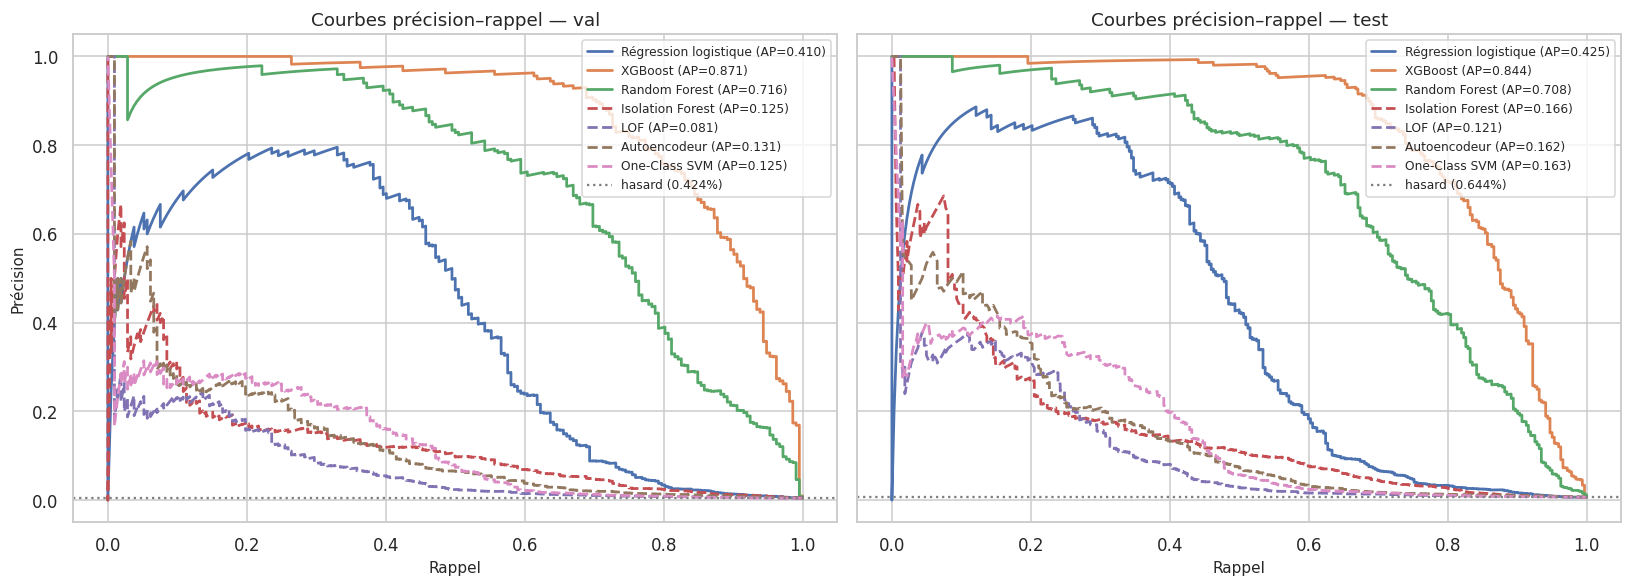

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, (split, y) in zip(axes, [("val", yva), ("test", yte)]):
    for name, s in SCORES.items():
        p, r, _ = precision_recall_curve(y, s[split])
        ap = average_precision_score(y, s[split])
        ax.plot(r, p, ls="-" if s["family"] == "Supervisé" else "--", lw=1.8, label=f"{name} (AP={ap:.3f})")
    ax.axhline(y.mean(), color="gray", ls=":", label=f"hasard ({y.mean():.3%})")
    ax.set_title(f"Courbes précision–rappel — {split}"); ax.set_xlabel("Rappel"); ax.legend(fontsize=8)
axes[0].set_ylabel("Précision"); plt.tight_layout(); plt.show()

## 4.4 Alert Budget k: Choice and Sensitivity Analysis

In [22]:
avg_fraud_day = yte.sum() / len(np.unique(days_te))
print(f"Fraudes moyennes par jour (test) : {avg_fraud_day:.1f} → k = {K_DAILY} correspond à ~{K_DAILY/avg_fraud_day:.1f} alertes par fraude réelle")
rows = []
for name, s in SCORES.items():
    r = {"Modèle": name}
    for k in K_LIST:
        p, rc = topk_daily(yte, s["test"], days_te, k)
        r[f"P@{k}"], r[f"R@{k}"] = p, rc
    rows.append(r)
display(pd.DataFrame(rows).set_index("Modèle").round(3))

Fraudes moyennes par jour (test) : 14.0 → k = 100 correspond à ~7.1 alertes par fraude réelle


,P@50,R@50,P@100,R@100,P@200,R@200
Modèle,,,,,,
Régression logistique,0.169,0.602,0.093,0.668,0.051,0.724
XGBoost,0.261,0.932,0.133,0.953,0.068,0.972
Random Forest,0.242,0.863,0.130,0.932,0.067,0.953
Isolation Forest,0.126,0.450,0.085,0.606,0.050,0.708
LOF,0.099,0.354,0.057,0.410,0.035,0.497
Autoencodeur,0.116,0.413,0.071,0.509,0.041,0.587
One-Class SVM,0.129,0.460,0.073,0.519,0.042,0.596


## 4.5 Optimal Threshold τ* via Business Cost Minimization

Modèle retenu pour l'application et l'explicabilité : XGBoost


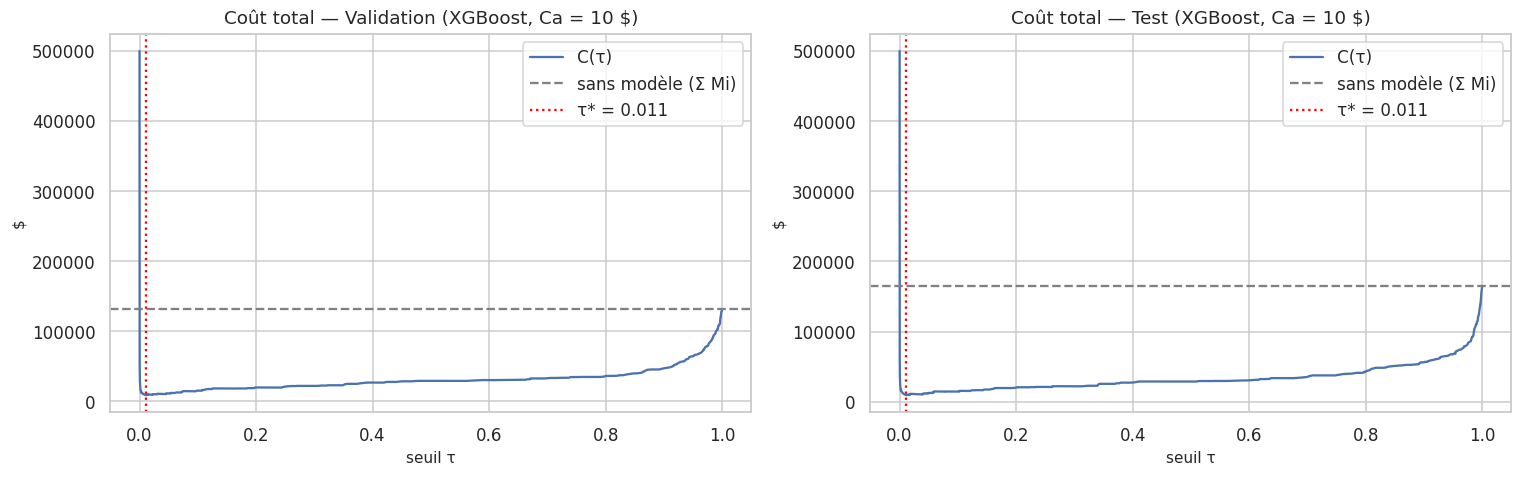

,Validation,Test (confirmation)
Coût avec modèle ($),8760.250,9684.220
Coût sans modèle ($),131632.270,165226.480
Économie nette ($),122872.020,155542.260
Alertes levées,630.000,734.000
Précision,0.324,0.399
Rappel,0.962,0.910
F2,0.690,0.725
MCC,0.556,0.599


,Ca ($),τ*,Alertes test,Économie test ($),Économie (%)
0,5,0.0108,734,159212.26,96.3600
1,10,0.0108,734,155542.26,94.1388
2,20,0.0223,572,148302.74,89.7572


In [23]:
sup_trees = [n for n in ["XGBoost", "Random Forest"]]
RETAINED = max(sup_trees, key=lambda n: average_precision_score(yva, SCORES[n]["val"]))
print("Modèle retenu pour l'application et l'explicabilité :", RETAINED)

sv, st = SCORES[RETAINED]["val"], SCORES[RETAINED]["test"]
cv = cost_curve(yva, amt_va, sv, CA); ct = cost_curve(yte, amt_te, st, CA)
tau_star = float(cv.loc[cv["cost"].idxmin(), "tau"])
cost_v, alert_v = cost_at(yva, amt_va, sv, tau_star, CA)
cost_t, alert_t = cost_at(yte, amt_te, st, tau_star, CA)
base_v, base_t = amt_va[yva == 1].sum(), amt_te[yte == 1].sum()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a_, c, base, lab in [(ax[0], cv, base_v, "Validation"), (ax[1], ct, base_t, "Test")]:
    a_.plot(c["tau"], c["cost"], label="C(τ)"); a_.axhline(base, color="gray", ls="--", label="sans modèle (Σ Mi)")
    a_.axvline(tau_star, color="red", ls=":", label=f"τ* = {tau_star:.3f}")
    a_.set_title(f"Coût total — {lab} ({RETAINED}, Ca = {CA:.0f} $)"); a_.set_xlabel("seuil τ"); a_.set_ylabel("$"); a_.legend()
plt.tight_layout(); plt.show()

summary = pd.DataFrame({
    "Validation": [cost_v, base_v, base_v - cost_v, int(alert_v.sum()), precision_score(yva, alert_v), recall_score(yva, alert_v), fbeta_score(yva, alert_v, beta=2), matthews_corrcoef(yva, alert_v)],
    "Test (confirmation)": [cost_t, base_t, base_t - cost_t, int(alert_t.sum()), precision_score(yte, alert_t), recall_score(yte, alert_t), fbeta_score(yte, alert_t, beta=2), matthews_corrcoef(yte, alert_t)],
}, index=["Coût avec modèle ($)", "Coût sans modèle ($)", "Économie nette ($)", "Alertes levées", "Précision", "Rappel", "F2", "MCC"])
display(summary.round(3))

# Sensitivity to analysis cost Ca
sens = []
for ca in [5, 10, 20]:
    c_ = cost_curve(yva, amt_va, sv, ca); tau_ = float(c_.loc[c_["cost"].idxmin(), "tau"])
    ct_, al_ = cost_at(yte, amt_te, st, tau_, ca)
    sens.append({"Ca ($)": ca, "τ*": tau_, "Alertes test": int(al_.sum()), "Économie test ($)": base_t - ct_, "Économie (%)": 100 * (base_t - ct_) / base_t})
display(pd.DataFrame(sens).round(4))

# STEP 5 — Explainable AI: SHAP, Reason Codes, LIME

In [24]:
import shap
from lime.lime_tabular import LimeTabularExplainer

clf_ret = get_clf(MODELS[RETAINED]["pipe"])
is_xgb = RETAINED == "XGBoost"

def tree_shap(clf, X_df):
    expl = shap.TreeExplainer(clf)
    sv_ = expl(X_df)
    vals, base = np.asarray(sv_.values), np.asarray(sv_.base_values)
    if vals.ndim == 3:                       # Random Forest: (n, d, 2 classes) -> fraud class
        vals, base = vals[:, :, 1], base[:, 1]
    return expl, vals, base

rng = np.random.default_rng(SEED)
samp = np.sort(rng.choice(len(Xte_df), size=min(SHAP_N, len(Xte_df)), replace=False))
expl_obj, phi, base = tree_shap(clf_ret, Xte_df.iloc[samp])
sv_global = shap.Explanation(values=phi, base_values=base, data=raw_te.iloc[samp].to_numpy(), feature_names=feature_names)

# Additivity property check: f(x) = φ0 + Σ φj
f_x = clf_ret.predict(Xte_df.iloc[samp], output_margin=True) if is_xgb else clf_ret.predict_proba(Xte_df.iloc[samp])[:, 1]
print("Additivité f(x) = φ0 + Σφj vérifiée :", np.allclose(base + phi.sum(1), f_x, atol=1e-3))

Additivité f(x) = φ0 + Σφj vérifiée : True


## 5.1 Global Explanation
### (a) Feature Importance Bar Plot with One-Hot Column Grouping

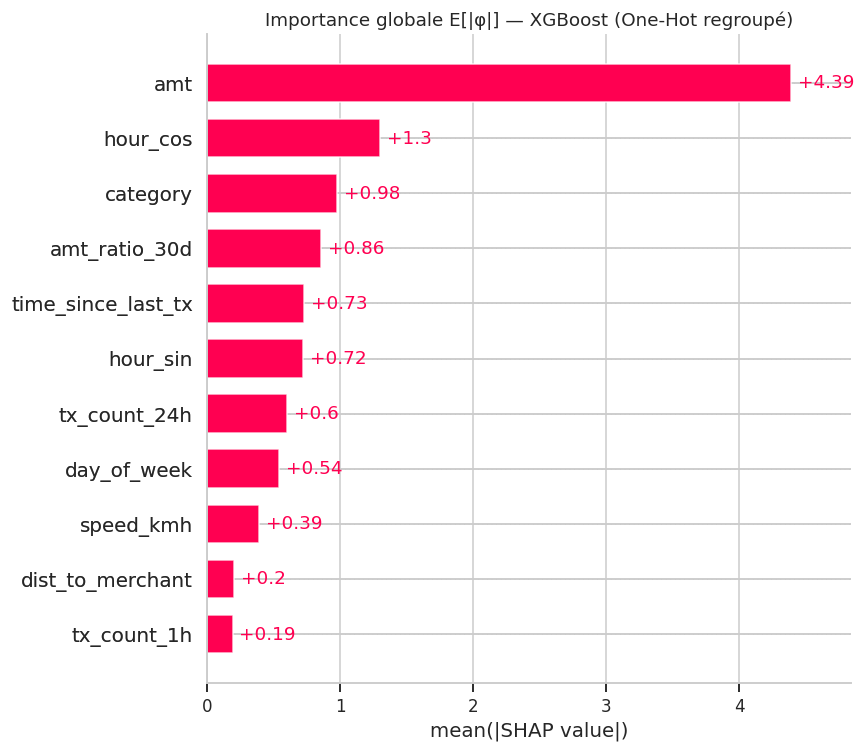

In [25]:
def group_onehot(expl, prefix="category_", new_name="category"):
    names = list(expl.feature_names)
    cat_idx = [i for i, n in enumerate(names) if n.startswith(prefix)]
    keep = [i for i in range(len(names)) if i not in cat_idx]
    vals = np.c_[expl.values[:, keep], expl.values[:, cat_idx].sum(axis=1)]
    data = np.c_[expl.data[:, keep], expl.data[:, cat_idx].argmax(axis=1)]
    return shap.Explanation(values=vals, base_values=expl.base_values, data=data,
                            feature_names=[names[i] for i in keep] + [new_name])

sv_grouped = group_onehot(sv_global)
shap.plots.bar(sv_grouped, max_display=15, show=False)
plt.title(f"Importance globale E[|φ|] — {RETAINED} (One-Hot regroupé)"); plt.tight_layout(); plt.show()

### (b) Beeswarm Plot and Dependence Plots

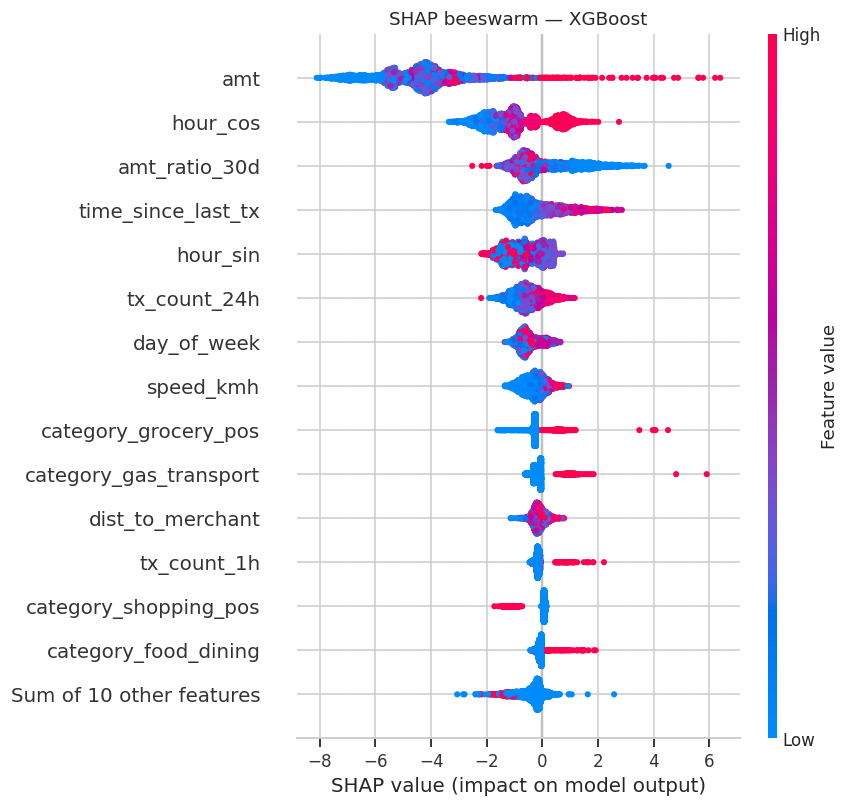

Background dataset has 150000 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=150000 when initializing the masker.


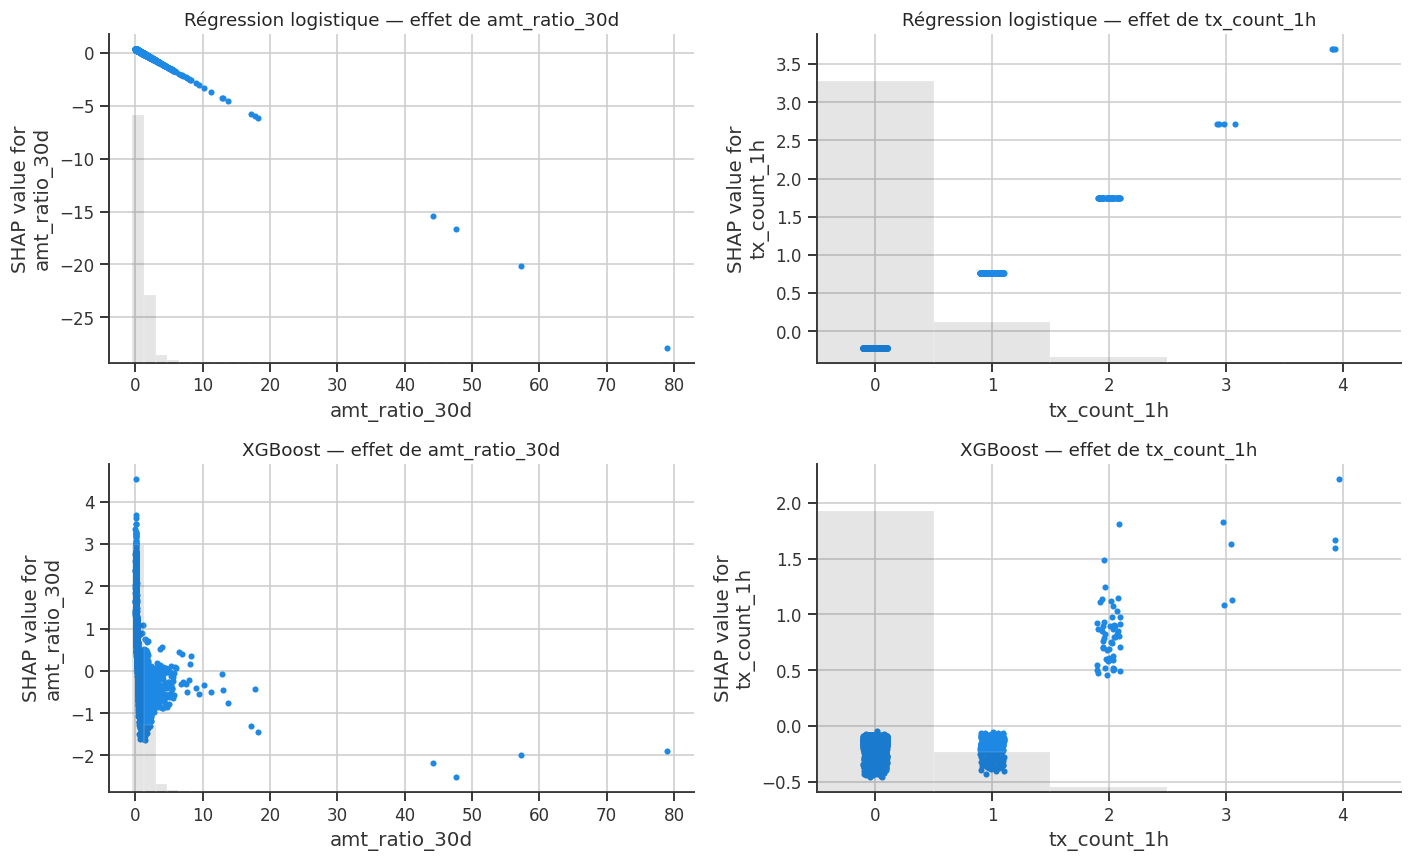

In [26]:
shap.plots.beeswarm(sv_global, max_display=15, show=False)
plt.title(f"SHAP beeswarm — {RETAINED}"); plt.tight_layout(); plt.show()

# Logistic Regression: LinearExplainer (exact)
lr_clf = get_clf(MODELS["Régression logistique"]["pipe"])
lin_expl = shap.LinearExplainer(lr_clf, Xtr_df)
lin_sv = lin_expl(Xte_df.iloc[samp])
sv_lin = shap.Explanation(values=lin_sv.values, base_values=lin_sv.base_values, data=raw_te.iloc[samp].to_numpy(), feature_names=feature_names)

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for j, feat_name in enumerate(["amt_ratio_30d", "tx_count_1h"]):
    shap.plots.scatter(sv_lin[:, feat_name], ax=axes[0, j], show=False)
    axes[0, j].set_title(f"Régression logistique — effet de {feat_name}")
    shap.plots.scatter(sv_global[:, feat_name], ax=axes[1, j], show=False)
    axes[1, j].set_title(f"{RETAINED} — effet de {feat_name}")
plt.tight_layout(); plt.show()

## 5.2 Local Alert Explanation

Parmi les 30 alertes les plus suspectes du test : 30 vraies fraudes (précision 100%)
Alerte inspectée : ligne test #10306 | rang 1 | montant 8.92 $ | catégorie gas_transport | fraude réelle = 1


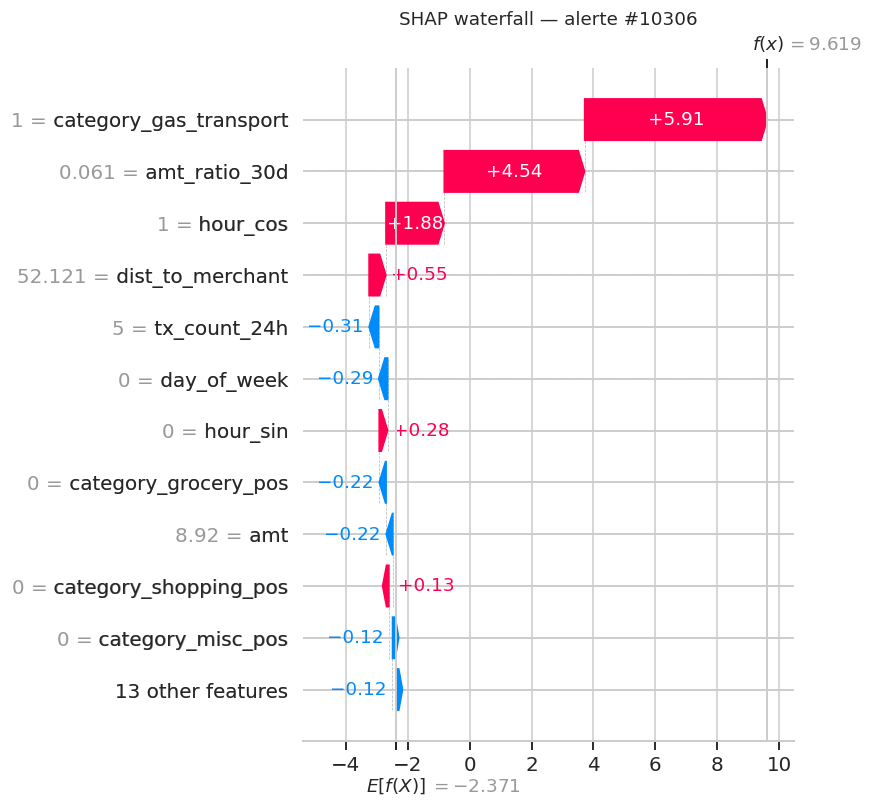

In [27]:
TOP = 30
top_idx = np.argsort(-SCORES[RETAINED]["test"])[:TOP]
_, phi_top, base_top = tree_shap(clf_ret, Xte_df.iloc[top_idx])
sv_top = shap.Explanation(values=phi_top, base_values=base_top, data=raw_te.iloc[top_idx].to_numpy(), feature_names=feature_names)

print(f"Parmi les {TOP} alertes les plus suspectes du test : {int(yte[top_idx].sum())} vraies fraudes (précision {yte[top_idx].mean():.0%})")
j_tp = int(np.where(yte[top_idx] == 1)[0][0]) if yte[top_idx].sum() > 0 else 0   # first true positive fraud in the alert queue
i_tp = top_idx[j_tp]
print(f"Alerte inspectée : ligne test #{i_tp} | rang {j_tp+1} | montant {test.amt.iloc[i_tp]:.2f} $ | catégorie {test.category.iloc[i_tp]} | fraude réelle = {yte[i_tp]}")

shap.plots.waterfall(sv_top[j_tp], max_display=12, show=False)
plt.title(f"SHAP waterfall — alerte #{i_tp}"); plt.tight_layout(); plt.show()

In [28]:
JOURS = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]

def reason_codes(phi_row, raw_row, hour, top_k=5, min_k=3):
    names = feature_names
    contrib = {}
    cat_cols = [n for n in names if n.startswith("category_")]
    for n, p in zip(names, phi_row):
        if n.startswith("category_"):            key = "category"
        elif n in ("hour_sin", "hour_cos"):     key = "hour"
        else:                                    key = n
        contrib[key] = contrib.get(key, 0.0) + p
    active_cat = max(cat_cols, key=lambda c: raw_row[c]).replace("category_", "")
    v = raw_row
    text = {
        "amt": f"Montant élevé : {v['amt']:,.2f} $",
        "amt_ratio_30d": f"Montant {v['amt_ratio_30d']:.1f}× supérieur à la moyenne des 30 derniers jours",
        "tx_count_1h": f"{int(v['tx_count_1h'])} transaction(s) sur la même carte dans l'heure précédente",
        "tx_count_24h": f"{int(v['tx_count_24h'])} transaction(s) sur la même carte dans les 24 h précédentes",
        "time_since_last_tx": ("Première transaction observée pour cette carte" if v["time_since_last_tx"] >= GAP_CAP else
                               f"Seulement {v['time_since_last_tx']/60:.0f} min depuis la transaction précédente" if v["time_since_last_tx"] < 3600 else
                               f"{v['time_since_last_tx']/3600:.1f} h depuis la transaction précédente"),
        "dist_to_merchant": f"Distance porteur–marchand inhabituelle : {v['dist_to_merchant']:.0f} km",
        "speed_kmh": f"Vitesse implicite de {v['speed_kmh']:.0f} km/h entre deux marchands consécutifs",
        "hour": f"Transaction à {hour} h (horaire atypique)",
        "day_of_week": f"Transaction un {JOURS[int(round(v['day_of_week']))]}",
        "category": f"Catégorie de marchand « {active_cat} » à risque",
    }
    pos = sorted([(k, p) for k, p in contrib.items() if p > 0], key=lambda kv: -kv[1])
    chosen = pos[:top_k] if len(pos) >= min_k else pos
    return [(text[k], p) for k, p in chosen]

rows = []
for rank, j in enumerate(range(min(5, TOP)), start=1):
    i = top_idx[j]
    codes = reason_codes(phi_top[j], raw_te.iloc[i], int(test.hour.iloc[i]))
    rows.append({"Rang": rank, "Score": round(float(SCORES[RETAINED]['test'][i]), 4), "Fraude réelle": int(yte[i]),
                 "Codes motifs": " | ".join(f"{t} ({p:+.2f})" for t, p in codes)})
display(pd.DataFrame(rows))
print("\nDétail de l'alerte inspectée :")
for t, p in reason_codes(phi_top[j_tp], raw_te.iloc[i_tp], int(test.hour.iloc[i_tp])):
    print(f"  • {t}  ({p:+.2f})")

,Rang,Score,Fraude réelle,Codes motifs
0,1,0.9999,1,Catégorie de marchand « gas_transport » à risq...
1,2,0.9998,1,Catégorie de marchand « gas_transport » à risq...
2,3,0.9998,1,Catégorie de marchand « gas_transport » à risq...
3,4,0.9997,1,Montant élevé : 304.17 $ (+4.71) | Catégorie d...
4,5,0.9997,1,Montant élevé : 320.34 $ (+4.84) | Catégorie d...



Détail de l'alerte inspectée :
  • Catégorie de marchand « gas_transport » à risque  (+5.58)
  • Montant 0.1× supérieur à la moyenne des 30 derniers jours  (+4.54)
  • Transaction à 0 h (horaire atypique)  (+2.16)
  • Distance porteur–marchand inhabituelle : 52 km  (+0.55)
  • Vitesse implicite de 100 km/h entre deux marchands consécutifs  (+0.09)


## 5.3 Additional Analyses
### (a) Decision Plot (SHAP Decision Plot)

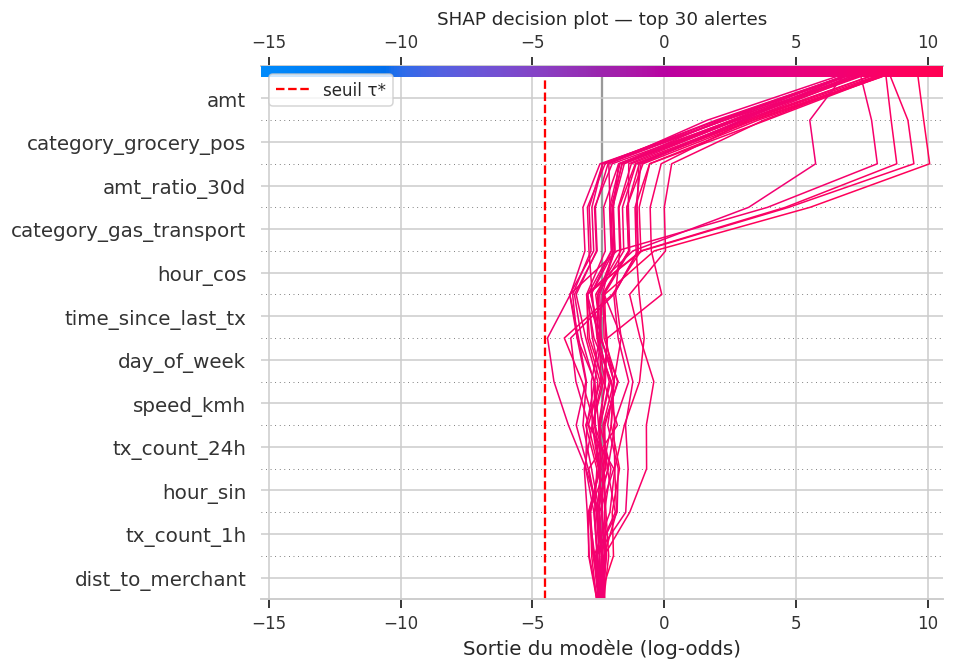

In [29]:
raw_ret_va = clf_ret.predict(Xva_df, output_margin=True) if is_xgb else clf_ret.predict_proba(Xva_df)[:, 1]
thr_model_space = float(raw_ret_va[SCORES[RETAINED]["val"] >= tau_star].min()) if (SCORES[RETAINED]["val"] >= tau_star).any() else float(raw_ret_va.max())
false_alerts = np.where(yte[top_idx] == 0)[0]
shap.decision_plot(float(base_top[0]), phi_top, features=raw_te.iloc[top_idx].to_numpy(), feature_names=feature_names,
                   highlight=list(false_alerts) if len(false_alerts) else None, link="identity",
                   feature_display_range=slice(-1, -13, -1), show=False)
plt.axvline(thr_model_space, color="red", ls="--", lw=1.5, label="seuil τ*")
plt.xlabel(f"Sortie du modèle ({'log-odds' if is_xgb else 'probabilité'})"); plt.legend(); plt.title(f"SHAP decision plot — top {TOP} alertes"); plt.show()

### (b) LIME: Local Explanation via Weighted Linear Regression

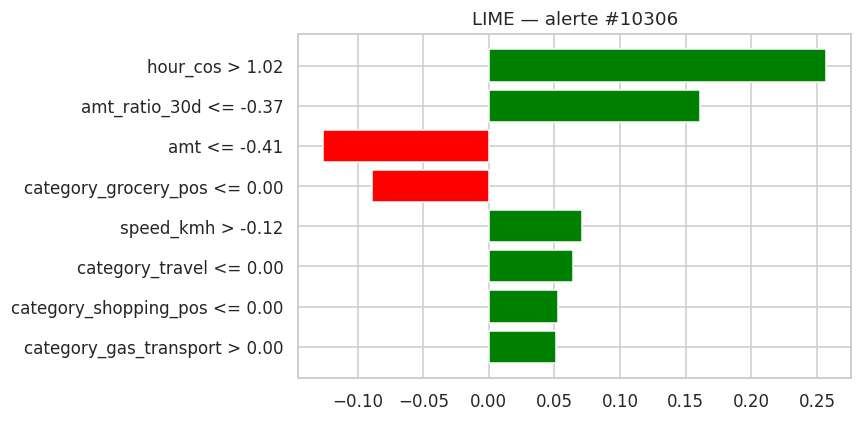

Variables dominantes SHAP : ['category', 'amt_ratio_30d', 'hour_cos', 'dist_to_merchant', 'tx_count_24h']
Variables dominantes LIME : ['hour_cos > 1.02', 'amt_ratio_30d <= -0.37', 'amt <= -0.41', 'category_grocery_pos <= 0.00', 'speed_kmh > -0.12']


In [30]:
def predict_proba_ret(X):
    p = sup_score(MODELS[RETAINED]["pipe"], MODELS[RETAINED]["beta"], pd.DataFrame(X, columns=feature_names))
    return np.c_[1 - p, p]

lime_explainer = LimeTabularExplainer(Xtr[np.random.default_rng(SEED).choice(len(Xtr), 20000, replace=False)],
                                      feature_names=feature_names, class_names=["normale", "fraude"],
                                      mode="classification", discretize_continuous=True, random_state=SEED)
lime_exp = lime_explainer.explain_instance(Xte[i_tp], predict_proba_ret, num_features=8, num_samples=3000)
fig = lime_exp.as_pyplot_figure(); fig.set_size_inches(8, 4); plt.title(f"LIME — alerte #{i_tp}"); plt.tight_layout(); plt.show()

shap_top5 = group_onehot(sv_top[j_tp:j_tp+1])
shap_series = pd.Series(shap_top5.values[0], index=shap_top5.feature_names).sort_values(key=np.abs, ascending=False)
print("Variables dominantes SHAP :", list(shap_series.index[:5]))
print("Variables dominantes LIME :", [t for t, _ in lime_exp.as_list()[:5]])

### (c) Multi-Model Comparison on the Same Case

In [31]:
def group_series(phi_vec, names):
    s = pd.Series(phi_vec, index=names)
    cat = s[[n for n in names if n.startswith("category_")]].sum()
    s = s[[n for n in names if not n.startswith("category_")]]
    s["category"] = cat
    return s

x_row = Xte_df.iloc[[i_tp]]
contribs = {}
contribs["Régression logistique"] = group_series(lin_expl(x_row).values[0], feature_names)
for nm, mdl in [("XGBoost", get_clf(MODELS["XGBoost"]["pipe"])), ("Random Forest", MODELS["Random Forest"]["pipe"])]:
    _, ph, _ = tree_shap(mdl, x_row)
    contribs[nm] = group_series(ph[0], feature_names)
try:
    iso_expl = shap.TreeExplainer(iso)
    probe = Xte_df.iloc[samp[:300]]
    sign = 1 if np.corrcoef(np.asarray(iso_expl.shap_values(probe)).sum(1), -iso.score_samples(probe.to_numpy()))[0, 1] > 0 else -1
    contribs["Isolation Forest"] = group_series(sign * np.asarray(iso_expl.shap_values(x_row))[0], feature_names)
except Exception as e:
    print("TreeExplainer sur Isolation Forest indisponible :", e)

comp = pd.DataFrame({nm: [f"{k} ({v:+.2f})" for k, v in s.sort_values(ascending=False).head(3).items()] for nm, s in contribs.items()},
                    index=["Motif 1", "Motif 2", "Motif 3"])
display(comp)


,Régression logistique,XGBoost,Random Forest,Isolation Forest
Motif 1,hour_cos (+2.61),category (+5.58),category (+0.18),hour_cos (+0.22)
Motif 2,amt_ratio_30d (+0.34),amt_ratio_30d (+4.54),hour_cos (+0.16),speed_kmh (+0.08)
Motif 3,category (+0.07),hour_cos (+1.88),amt_ratio_30d (+0.06),dist_to_merchant (-0.01)


# Summary and Artifact Export

In [32]:
os.makedirs("artifacts", exist_ok=True)
joblib.dump({"preprocessor": preprocessor, "feature_names": feature_names, "num_feats": NUM_FEATS, "cat_feats": CAT_FEATS,
             "models": {k: {"pipe": v["pipe"], "beta": v["beta"]} for k, v in MODELS.items()},
             "iso_forest": iso, "retained": RETAINED, "tau_star": tau_star, "Ca": CA, "k_daily": K_DAILY,
             "master_table": master}, "artifacts/fraud_artifacts.joblib")
master.to_csv("artifacts/master_table.csv", index=False)
print("Artefacts sauvegardés dans ./artifacts :", os.listdir("artifacts"))

Artefacts sauvegardés dans ./artifacts : ['master_table.csv', 'fraud_artifacts.joblib']
